# Random Forest
---

* Es un método **Ensemble Methods** (aprendizaje por conjuntos) 
* Es un algoritmo de aprendizaje supervisado que se utiliza tanto para **clasificación** como para **regresión**
* Fue desarrollado por Leo Breiman y Adele Cutler
* Se basa en la idea de construir múltiples árboles de decisión y combinar sus resultados para mejorar la precisión y evitar el sobreajuste

## Funcionamiento

1. **Bootstrap**: Se generan múltiples subconjuntos de datos (con reemplazo) a partir del conjunto de entrenamiento original
2. **Árboles de decisión**: Para cada subconjunto, se construye un árbol de decisión. Pero en cada nodo, en lugar de considerar todas las variables, se selecciona aleatoriamente un subconjunto de ellas
3. **Votación o promedio**: En clasificación, cada árbol vota por una clase y se elige la clase con más votos. En regresión, se promedia la predicción de todos los árboles

## Ventajas y desventajas

* **Ventajas**:
    * **Robusto al sobreajuste**: Al promediar muchos árboles, se reduce la varianza
    * **Manejo de datos faltantes y ruido**
    * **Importancia de variables**: Permite evaluar qué variables son más relevantes para la predicción
    * **Escalable**: Funciona bien con grandes volúmenes de datos
* **Desventajas**:
    * **Menos interpretabilidad** que un solo árbol de decisión
    * **Más costoso computacionalmente**
    * Puede ser sensible a clases desbalanceadas si no se ajusta correctamente

## Clasificadores por Votación

* Logistic Regression
* SVM Classifier
* Random Forest Classifier
* Other...

## ¿Por qué funciona?

* **Analogía de la moneda sesgada** (marcada)
    * Moneda con **51% probabilidad de cara y 49% cruz**
    * Si lanzas **1.000 veces**, obtendrás ≈ **510 caras vs 490 cruces** => mayoría de caras
    * Probabilidad de mayoría de caras:
        * **1.000 lanzamientos** => **~75%**
        * **10.000 lanzamientos** => **>97%**

* **Ley de los Grandes Números**
    * A medida que aumentan los lanzamientos:
        * La proporción de caras => **se aproxima al 51% real**
        * Las series terminan **consistentemente por encima del 50%**

## Relación con Voting Classifier

* Cada clasificador débil = **moneda ligeramente sesgada**
* Combinando muchos clasificadores:
    * **Más votos => mayor precisión global**
* Incluso si cada modelo es débil, el conjunto puede ser **un aprendiz fuerte**

## Voting Classifier

* **¿Qué es?**
    * Combina predicciones de varios clasificadores
    * Predice la clase con mayoría de votos => **Hard Voting**
    * Variante: **Soft Voting** (usa probabilidades promedio)

* **Ventajas**
    * **Mejor precisión** que el mejor clasificador individual
    * Funciona incluso con **aprendices débiles**, si son:
        * **Suficientemente numerosos**
        * **Diversos** (no todos cometen los mismos errores)

## ¿Cuál es el problema que tienen los árboles de clasificación o los de regresión?

* En general los datos se ajustan muy bien a los de entrenamiento, con los datos de test no se ajustan tan bien
* Sobreajuste o overfiting
    * Entrenamiento: $\downarrow$ SESGO BAJO (diferencia entre el valor predicho y el valor real)
    * Test: $\uparrow$ VARIANZA ALTA

* **Compromiso Sesgo-Varianza**
    * **Sesgo bajo**: se ajustan muy bien a los datos de entrenamiento
    * **Varianza alta**: en los datos de prueba, sensibles a cambios en los datos => árboles muy diferentes
* **Consecuencia**
    * Buen desempeño en entrenamiento, pero baja capacidad de generalización
    * Predicciones inestables con datos nuevos

## Solución – Árboles de Precisión (Ensemble)

* **Objetivo**: mantener sesgo bajo y reducir varianza
* **Cómo se logra**:
    * Entrenar varios árboles en lugar de uno
    * Usar subconjuntos aleatorios de datos para cada árbol
    * Agregar resultados (votación o promedio) para la predicción final
* **Ventaja**: árboles menos precisos tienen menor impacto => modelo más robusto

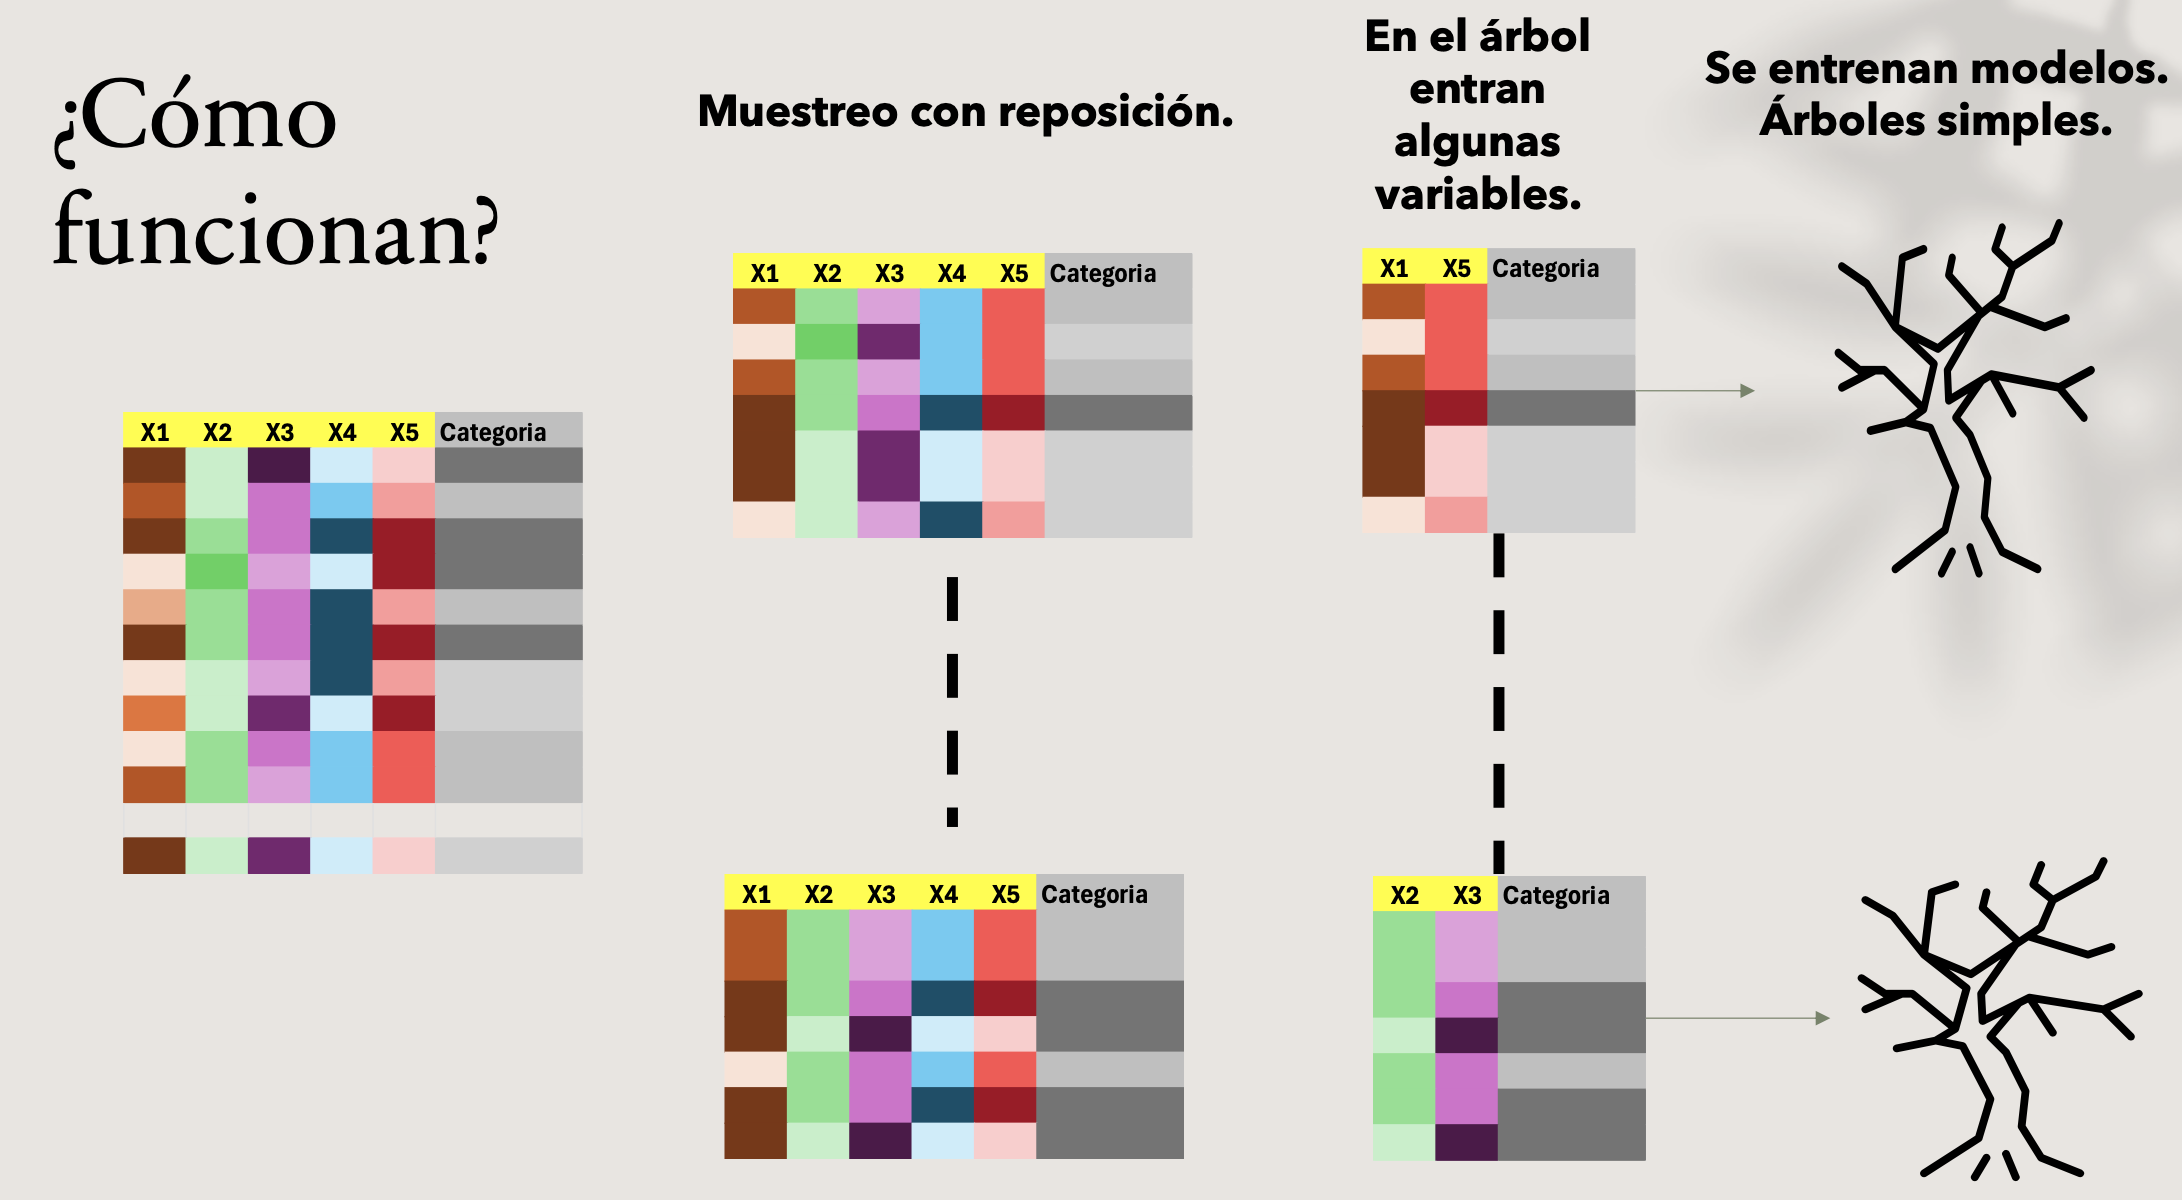

* Cada fila => una observación
* Cada columna => una variable
* Por ejemplo, dataset de 12 observaciones x 5 variables

1. **Bootstrapping**: Muestreo con reposición. Se generan subconjuntos (de 12 observaciones x 5 variables) mediante muestreo con reposición (misma probabilidad de obtener una observacion porque si la saco, vuelvo a ponerla, entonces alta probabilidad que tenga dos o más veces la misma observación. Es selección aleatoria)
2. Seleccionar variables de forma aleatoria de cada subconjunto y esto va a entrenar a cada árbol simple

* **Clasificación**: se escoge la categoría asignada por la mayoría de los árboles
* **Regresión**: se promedia la predicción hecha por los árboles

## Pasos

1. **Bootstrapping en Random Forest**
    * Se parte del conjunto de datos original con n observaciones
    * Para cada árbol del bosque: Se toma una **muestra bootstrap** del conjunto original (mismo tamaño n, con reemplazo)
    * Esto significa que algunas observaciones se repiten y otras quedan fuera (estas últimas se llaman **out-of-bag**)

2. **Entrenamiento de cada árbol**
    * Cada árbol se entrena con su muestra bootstrap
    * Además, en cada división del árbol, se **selecciona aleatoriamente un subconjunto** de variables (**feature bagging**)
    * Esto **introduce variabilidad y reduce la correlación** entre árboles

3. **Predicción y agregación**
    * Cada árbol produce una predicción
    * El modelo final combina todas las predicciones:
        * **Clasificación**: votación mayoritaria
        * **Regresión**: promedio

* **¿Por qué es importante el bootstrapping?**
    * Permite que cada árbol vea una versión distinta del dataset => **reduce varianza**
    * Genera diversidad entre árboles, lo que mejora la capacidad de generalización
    * Las observaciones **out-of-bag** se usan para estimar el error sin necesidad de un conjunto de validación adicional

## Diagrama del proceso de bootstrapping en Random Forest

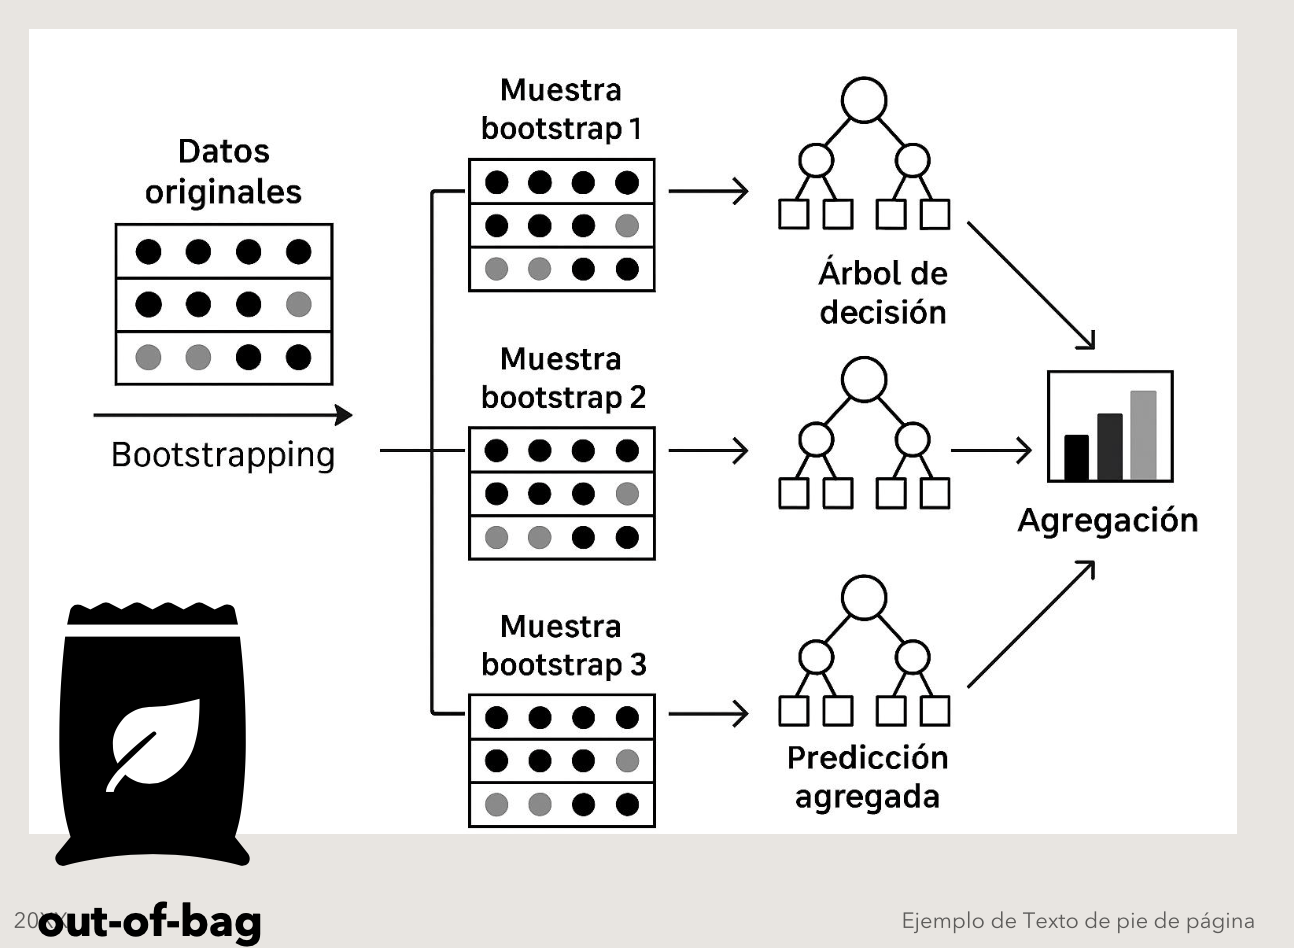

* **Datos originales** => se generan varias **muestras bootstrap** (con reemplazo)
* Cada muestra entrena un **árbol de decisión**
* Las predicciones de todos los árboles se **agregan** (votación o promedio) para obtener la predicción final

## Hiperparámetros

Con los datos fuera de la bolsa puedo medir el error:

* **Nro de árboles** (mayor cantidad de árboles menor es el error)
* **Nro de características** (encontrar la cantidad que minimice el error, mayor cantidad de características mayor es el error)
* **Nro total de hojas** (encontrar la cantidad que minimice el error, mayor cantidad de hojas mayor es el error)

## En Random Forest, las métricas para evaluar la calidad del modelo dependen del tipo de problema

* **Clasificación**
    * Exactitud (Accuracy)
    * Matriz de Confusión
    * Precisión, Recall y F1-Score
    * Error Out-of-Bag (OOB): Estimación interna del error usando las observaciones no incluidas en cada bootstrap
* **Regresión**
    * Error Cuadrático Medio
    * Raíz del Error Cuadrático Medio
    * Coeficiente de Determinación (R²): Mide qué proporción de la variabilidad se explica por el modelo
    * Error Out-of-Bag (OOB): También aplicable en regresión como estimación interna

**Bagging = Boostraping + Agregation**